# OULAD baseline model comparison

This notebook is an interactive view of the reusable OULAD pipeline. It does not contain the dataset or duplicate the cleaning and feature logic.

The current task is enrollment-level risk classification. The enrollment is the statistical unit: one student-course-presentation combination, not necessarily one unique student. All counts, rates, and performance metrics therefore refer to enrollments.

- `Fail` or `Withdrawn` → risk `1`
- `Pass` or `Distinction` → risk `0`

The features currently include student attributes, assessment aggregates, registration fields, and optional VLE activity aggregates. These families are targeted because they represent the learner context, observed academic progress, enrollment timing, and recorded online engagement that a planner could use to prioritize review. VLE clicks are activity counts, not study duration, and none of these variables is treated as a causal explanation of risk.

## Notebook map

This notebook assumes the data layer has been reviewed in `01_oulad_data_exploration.ipynb`. It then creates the enrollment-level feature matrix, uses student-grouped train/validation/locked-test partitions for all models, compares imbalance-aware metrics, and records why the selected model is only a baseline.

## 1. Locate the repository and data

Place the OULAD CSV release in `data/raw/oulad/`. If processed tables already exist, this notebook uses them; otherwise it creates them with the project cleaner.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / 'src/data/cleaner.py').exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW_DIR = ROOT / 'data/raw/oulad'
PROCESSED_DIR = ROOT / 'data/processed/oulad'
DATA_DIR = PROCESSED_DIR if (PROCESSED_DIR / 'studentInfo.csv').exists() else RAW_DIR

from src.data.cleaner import clean_oulad_tables, write_clean_tables
from src.data.loader import load_oulad_tables
from src.features.feature_engineering import build_oulad_features
from src.models.baseline import train_baselines
from src.models.baseline import split_baseline_data

print(f'Repository: {ROOT}')
print(f'Data directory: {DATA_DIR}')

Repository: D:\AI PROJECTS\C++\Smart-Study-Planner
Data directory: D:\AI PROJECTS\C++\Smart-Study-Planner\data\processed\oulad


In [2]:
raw_tables = load_oulad_tables(DATA_DIR)
cleaned_tables = clean_oulad_tables(raw_tables)

if DATA_DIR == RAW_DIR:
    write_clean_tables(
        cleaned_tables,
        PROCESSED_DIR,
        raw_row_counts={name: len(frame) for name, frame in raw_tables.items()},
    )

table_summary = pd.DataFrame(
    [
        {'table': name, 'rows': len(frame), 'columns': len(frame.columns)}
        for name, frame in cleaned_tables.items()
    ]
).sort_values('table')
display(table_summary.reset_index(drop=True))

,table,rows,columns
0,assessments,206,6
1,courses,22,3
2,studentAssessment,173912,5
3,studentInfo,32593,12
4,studentRegistration,32593,5
5,studentVle,10655280,6
6,vle,6364,6


### Why these checks matter

The target is enrollment-level rather than student-level. The same student can appear in multiple course presentations. The class counts and missing-value checks are shown before training so that metric interpretation is tied to the actual population used. Class proportions are descriptive properties of this modeling population, not estimates of a wider population prevalence.

## 2. Data-quality and outcome checks

Missing scores remain missing. They are not interpreted as zero because an unrecorded assessment does not establish zero performance. Invalid outcome labels are excluded from supervised training by the feature builder because a supervised metric requires a known reference label.

In [3]:
student_info = cleaned_tables['studentInfo']
student_assessment = cleaned_tables['studentAssessment']

quality = pd.Series({
    'enrollments': len(student_info),
    'assessment_records': len(student_assessment),
    'known_scores': int(student_assessment['score'].notna().sum()),
    'missing_scores': int(student_assessment['score'].isna().sum()),
    'minimum_known_score': student_assessment['score'].min(),
    'maximum_known_score': student_assessment['score'].max(),
})
display(quality.to_frame('value'))
display(student_info['final_result'].value_counts(dropna=False).rename_axis('final_result').to_frame('enrollments'))

,value
enrollments,32593.0
assessment_records,173912.0
known_scores,173739.0
missing_scores,173.0
minimum_known_score,0.0
maximum_known_score,100.0


,enrollments
final_result,
Pass,12361
Withdrawn,10156
Fail,7052
Distinction,3024


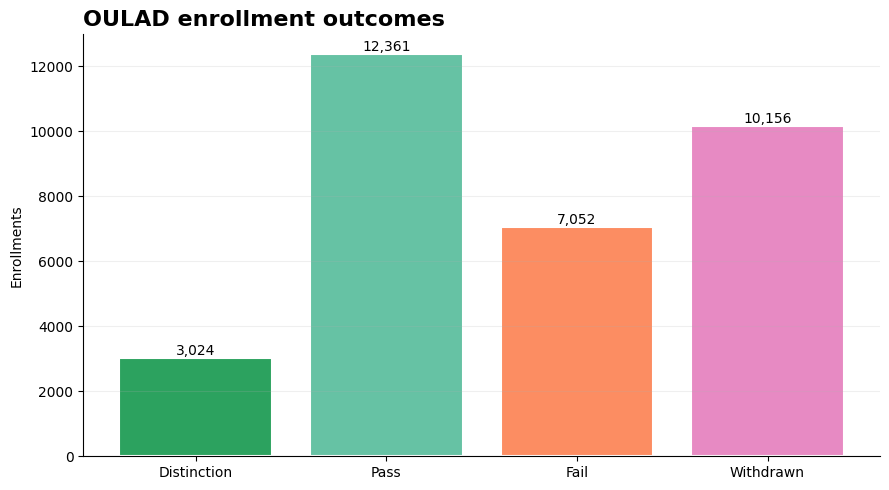

In [4]:
# Colorful outcome distribution
outcome_counts = student_info['final_result'].value_counts().reindex(
    ['Distinction', 'Pass', 'Fail', 'Withdrawn']
)
colors = ['#2ca25f', '#66c2a4', '#fc8d62', '#e78ac3']
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(outcome_counts.index, outcome_counts.values, color=colors, edgecolor='white', linewidth=1.5)
ax.set_title('OULAD enrollment outcomes', loc='left', fontsize=16, weight='bold')
ax.set_ylabel('Enrollments')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{int(bar.get_height()):,}',
            ha='center', va='bottom', fontsize=10)
fig.tight_layout()
plt.show()

### Model input boundary

The feature builder keeps identifiers and `final_result` for inspection, but the baseline model removes them. The model receives demographic/enrollment fields and aggregated assessment, registration, and optional activity features. Imputation and one-hot encoding happen inside each fitted pipeline after the train/test split. This ordering prevents preprocessing statistics from the holdout set from influencing model fitting.

## 3. Extract enrollment-level features

The feature builder joins assessment definitions to student assessment records, aggregates activity by enrollment, and creates the binary `target_risk`. Student and presentation identifiers are retained for inspection but removed from model inputs. Aggregation produces one modeling row per target unit and prevents enrollments with more recorded events from receiving unintended extra weight. The resulting signals are relevant to a study planner because they can support prioritization of learners for timely academic support; they do not themselves specify a study schedule or prove which intervention will work.

In [5]:
features = build_oulad_features(cleaned_tables, clean=False)
print(f'Feature rows: {len(features):,}')
print(f'Feature columns: {len(features.columns):,}')
display(features.head())
display(features['target_risk'].value_counts().rename_axis('target_risk').to_frame('enrollments'))

Feature rows: 32,593
Feature columns: 24


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,assessment_score_mean,assessment_score_std,assessment_score_min,assessment_score_max,assessment_score_missing,date_registration,date_unregistration,vle_clicks,vle_active_days,vle_resources
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,82.0,3.082207,78.0,85.0,0.0,-159.0,NaN,934.0,40.0,55.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,66.4,4.335897,60.0,70.0,0.0,-53.0,NaN,1435.0,80.0,84.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,NaN,NaN,NaN,NaN,NaN,-92.0,12.0,281.0,12.0,22.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,76.0,6.892024,71.0,88.0,0.0,-52.0,NaN,2158.0,123.0,82.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,54.4,20.513410,30.0,75.0,0.0,-176.0,NaN,1034.0,70.0,66.0


,enrollments
target_risk,
1,17208
0,15385


In [6]:
missingness = (
    features.isna().mean().sort_values(ascending=False).rename('missing_share').to_frame()
)
display(missingness[missingness['missing_share'] > 0].head(20))

,missing_share
date_unregistration,0.681772
assessment_score_std,0.285092
assessment_score_mean,0.207805
assessment_score_min,0.207805
assessment_score_max,0.207805
assessment_score_missing,0.207100
assessment_count,0.207100
vle_active_days,0.103243
vle_resources,0.103243
vle_clicks,0.103243


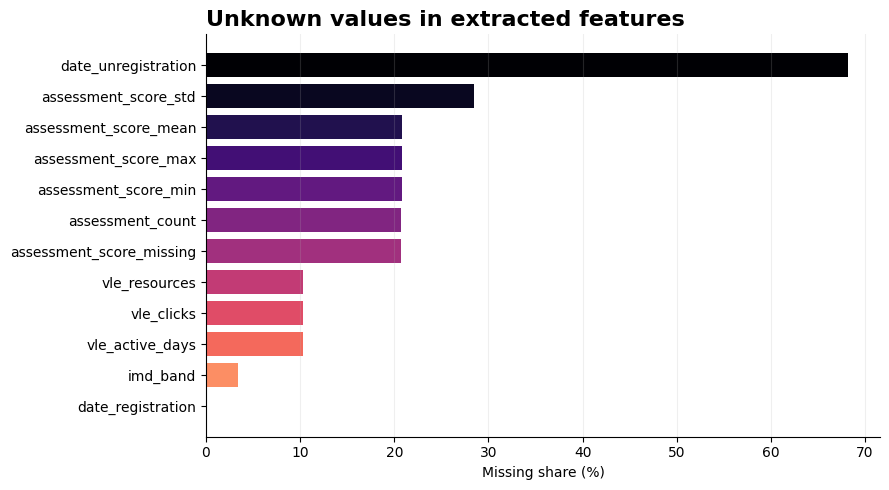

In [7]:
# Colorful missingness profile
missing_plot = missingness[missingness['missing_share'] > 0].head(12).sort_values('missing_share')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(missing_plot.index, missing_plot['missing_share'] * 100,
        color=plt.cm.magma_r(range(40, 40 + 20 * len(missing_plot), 20)))
ax.set_title('Unknown values in extracted features', loc='left', fontsize=16, weight='bold')
ax.set_xlabel('Missing share (%)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

### Why these four models

- Logistic regression is a transparent linear reference.
- Random forest provides a nonlinear bagging model.
- Extra trees adds stronger randomization and nonlinear interactions.
- Histogram gradient boosting is a compact boosting model for tabular data.

Logistic regression provides an interpretable linear reference; random forest provides nonlinear bagging; extra trees increases randomization in tree construction; and histogram gradient boosting provides a compact boosting model for tabular data. This model set is appropriate for OULAD because the extracted data are moderate-sized, enrollment-level tabular records with mixed numerical and categorical features: learner attributes, course and presentation fields, assessment-score aggregates, registration variables, and VLE activity aggregates. The comparison therefore tests additive relationships, nonlinear bagging, additional tree randomization, and sequential boosting without introducing unnecessary deep-learning complexity at the baseline stage.

The purpose of the baseline set is methodological as well as predictive. Logistic regression establishes an interpretable lower-complexity reference; random forest tests whether interactions and nonlinear decision rules improve prediction; extra trees tests whether stronger split randomization improves generalization; and histogram gradient boosting tests a different ensemble strategy that can learn threshold-based tabular patterns efficiently. All four models receive the same feature matrix, preprocessing, partitions, and random seed, so the comparison is attributable as far as possible to the model family rather than to different data preparation.

These models are baselines, not a claim of universal optimality. The grouped train/validation/locked-test comparison establishes a reproducible reference before more complex methods are considered. Probability calibration, intervention-threshold analysis, fairness review, and prospective evaluation remain necessary before deployment. PR-AUC is primary under class imbalance; validation ROC-AUC, validation balanced accuracy, and validation F1 are tie-breakers. The final test partition is not used for model selection.

## 4. Compare four baseline models

Every model uses the same deterministic student-grouped train/validation/locked-test partitions with `random_state=42`. Grouping prevents one learner from appearing in more than one partition, while the fixed seed makes the comparison reproducible. Selection prioritizes validation PR-AUC, then validation ROC-AUC, validation balanced accuracy, and validation F1.

In [8]:
best_name, fitted_models, model_results = train_baselines(features)
comparison = (
    pd.DataFrame(model_results).T
    .sort_values(['roc_auc', 'balanced_accuracy', 'f1'], ascending=False)
)
display(comparison[['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc']])
print(f'Selected model: {best_name}')

D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
hist_gradient_boosting,0.936566,0.938232,0.969113,0.908922,0.938053,0.981546
random_forest,0.933382,0.934898,0.96361,0.908227,0.935099,0.98036
extra_trees,0.934607,0.93621,0.966215,0.907995,0.936201,0.980302
logistic_regression,0.854396,0.855132,0.877354,0.842178,0.859406,0.931963


Selected model: hist_gradient_boosting


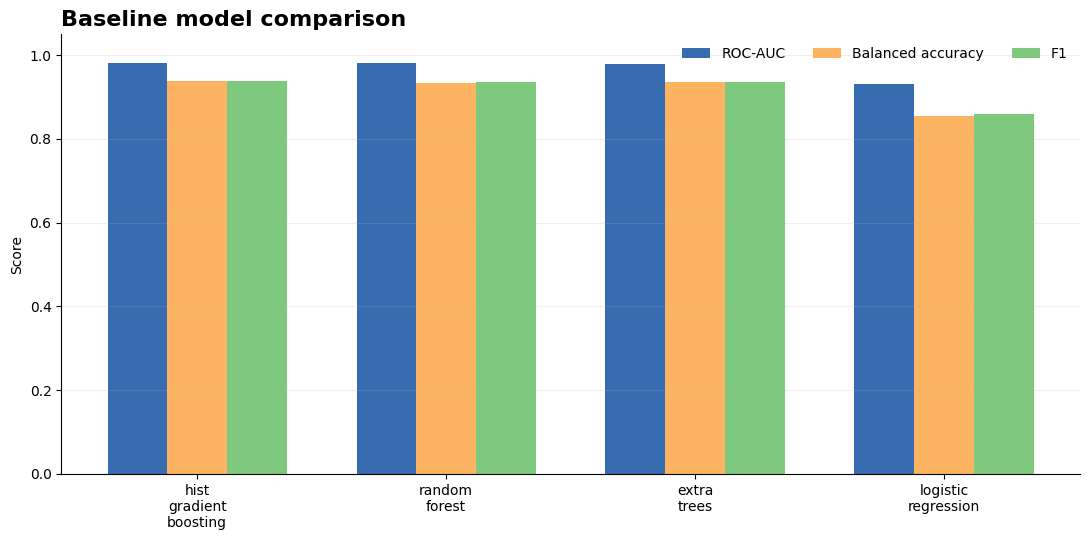

In [9]:
# Colorful model comparison
metric_names = ['roc_auc', 'balanced_accuracy', 'f1']
metric_labels = ['ROC-AUC', 'Balanced accuracy', 'F1']
metric_colors = ['#386cb0', '#fdb462', '#7fc97f']
fig, ax = plt.subplots(figsize=(11, 5.5))
x = range(len(comparison.index))
width = 0.24
for offset, metric, label, color in zip([-width, 0, width], metric_names, metric_labels, metric_colors):
    values = comparison[metric].astype(float).values
    ax.bar([position + offset for position in x], values, width, label=label, color=color)
ax.set_xticks(list(x), [name.replace('_', '\n') for name in comparison.index])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Baseline model comparison', loc='left', fontsize=16, weight='bold')
ax.legend(frameon=False, ncols=3)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

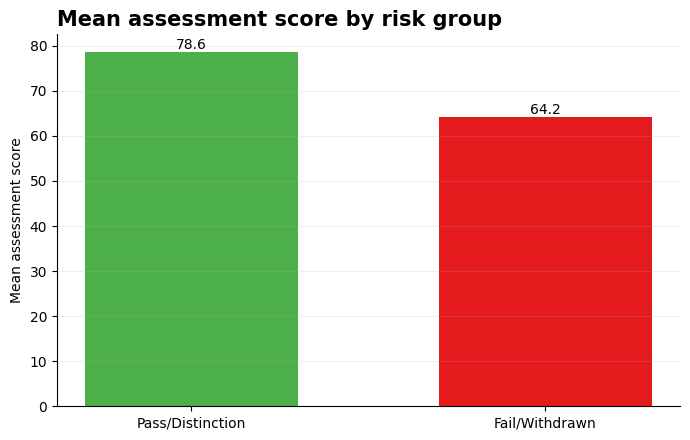

In [10]:
# Assessment-score profile by risk label
score_by_risk = features.groupby('target_risk')['assessment_score_mean'].mean().reindex([0, 1])
score_labels = ['Pass/Distinction', 'Fail/Withdrawn']
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(score_labels, score_by_risk.values, color=['#4daf4a', '#e41a1c'], width=0.6)
ax.set_title('Mean assessment score by risk group', loc='left', fontsize=15, weight='bold')
ax.set_ylabel('Mean assessment score')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.1f}',
            ha='center', va='bottom', fontsize=10)
fig.tight_layout()
plt.show()

### Confusion matrices before cutoff application

Each confusion matrix counts correct and incorrect predictions on the shared holdout. The rows are the actual labels and the columns are the predicted labels: 0 means Pass/Distinction and 1 means Fail/Withdrawn. These counts make the precision/recall trade-off visible, especially for risk screening. A false negative is an actual risk enrollment that was not flagged; a false positive is a reference-class enrollment that was flagged.

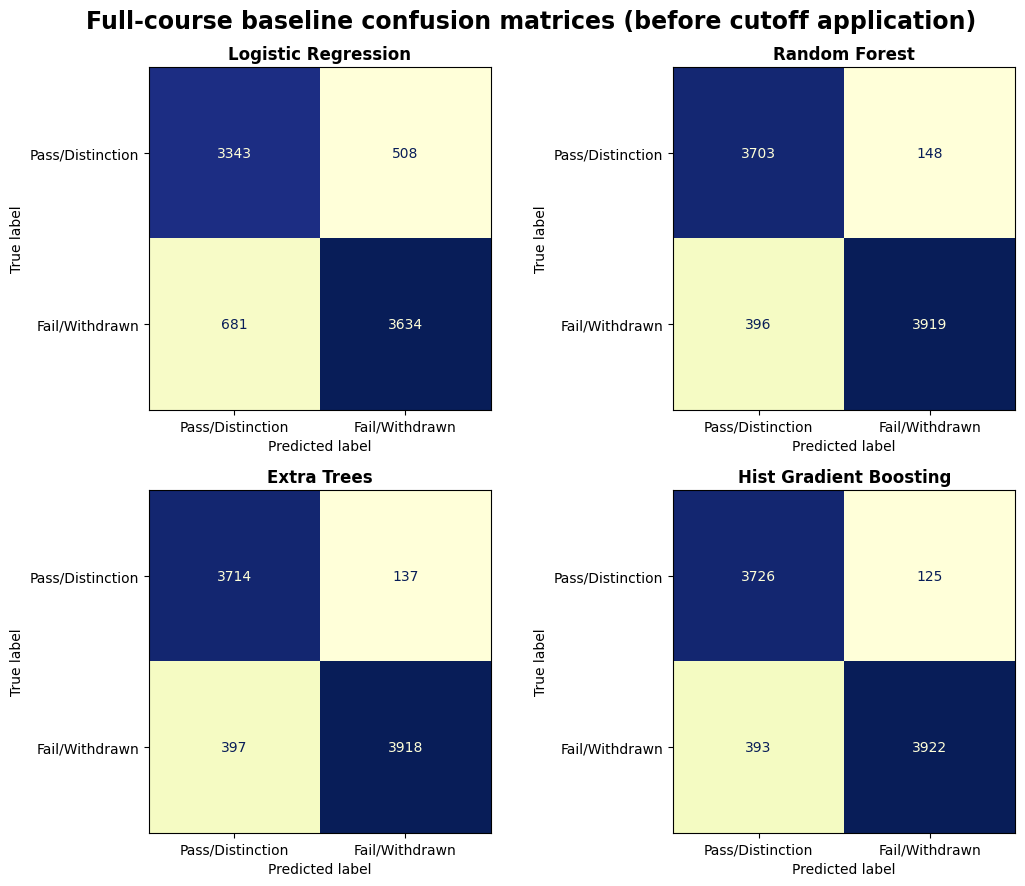

In [11]:
# Full-course confusion matrices before cutoff application
_, test_features, _, test_target = split_baseline_data(features, test_size=0.25, random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (model_name, model) in zip(axes.ravel(), fitted_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        test_target,
        model.predict(test_features),
        display_labels=['Pass/Distinction', 'Fail/Withdrawn'],
        cmap='YlGnBu',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(model_name.replace('_', ' ').title(), weight='bold')
fig.suptitle('Full-course baseline confusion matrices (before cutoff application)', fontsize=17, weight='bold', x=0.5, y=0.98)
fig.tight_layout()
plt.show()

### Interpretation of the model comparison

The chart compares models on exactly the same holdout rows. A higher score indicates better performance for that metric on this split; it does not prove that the model will perform equally well on a future cohort. The selected model should be re-evaluated after a prediction cutoff and time-aware split are introduced. The comparison is a benchmark, not an inferential test that establishes one model as universally superior.

## 5. Interpretation and limitations

The selected model is a benchmark for enrollment-risk prediction. The current features aggregate full-course assessment and VLE information while predicting the final outcome. That means these results are retrospective and may include information unavailable at an early prediction date.

The next modeling iteration should define a prediction cutoff, use time-aware features and splits, calibrate risk thresholds, and keep the predictive model separate from the study-schedule optimizer. Threshold selection should ultimately be based on the relative costs of missed support opportunities and unnecessary interventions, not on aggregate accuracy alone.

### Formal rationale for the baseline comparison

A baseline comparison is necessary before more complex modeling because it establishes a reproducible reference point. The four selected classifiers represent complementary assumptions. Logistic regression provides a transparent linear benchmark and shows how much performance can be obtained from additive relationships. Random forest provides nonlinear decision rules through bagging and is useful when interactions between learner, assessment, and activity variables may matter. Extra trees increases randomization in tree construction and tests whether stronger partition diversity improves generalization. Histogram gradient boosting provides a compact sequential ensemble that can capture nonlinear structure efficiently in tabular data.

All four models receive the same feature matrix, preprocessing logic, training rows, holdout rows, and random seed. This is essential for a meaningful comparison: if models were evaluated on different samples or preprocessing rules, a difference in metrics could reflect a difference in data rather than a difference in the classifier. Median imputation, categorical imputation, scaling where required, and one-hot encoding are fitted inside each pipeline after splitting so that the holdout set cannot influence the learned preprocessing parameters.

The student-grouped train/validation/locked-test split is used as a deterministic benchmark. Grouping prevents repeated learners from appearing in multiple partitions. The fixed random state makes the result reproducible, but it does not remove sampling uncertainty. A future study should use repeated or temporal validation to determine whether the ranking persists across cohorts.

The metric selection rule prioritizes validation PR-AUC, then validation ROC-AUC, validation balanced accuracy, and validation F1. PR-AUC is useful when the risk class is uncommon. ROC-AUC supports ranking, balanced accuracy prevents performance on the more common class from dominating the summary, and F1 summarizes the precision-recall trade-off. Confusion matrices remain necessary because aggregate metrics do not show whether the practical error is a missed-risk learner or an unnecessary support flag.

The comparison is relevant to the Smart Study Planner because the planner needs a reliable risk-screening component before it can decide which learners should receive additional review or support. It does not determine a study schedule, prescribe an intervention, or establish that an intervention improves outcomes. Those decisions require calibrated probabilities, operational thresholds, prospective validation, and a separate policy layer.